# Day 19: Capstone build, part 2


## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                              confusion_matrix, classification_report)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap
import joblib

## Rebuilding yesterday's split

Same URL, same cleaning steps, same random_state=42, so this lines up exactly with Day 18.

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

target = df["Churn"]
features = df.drop(columns=["Churn"])
cat_cols = features.select_dtypes(include="object").columns.tolist()
num_cols = features.select_dtypes(exclude="object").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, stratify=target, random_state=42)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

## Trying stronger models

Bagging with Random Forest, and boosting with XGBoost and LightGBM, both handling class imbalance in their own way (class_weight for the sklearn side, scale_pos_weight for XGBoost).

In [3]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

log_reg = Pipeline([("pre", preprocessor), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
rf = Pipeline([("pre", preprocessor), ("clf", RandomForestClassifier(class_weight="balanced", random_state=42))])
xgb = Pipeline([("pre", preprocessor), ("clf", XGBClassifier(
    eval_metric="logloss", random_state=42, scale_pos_weight=pos_weight))])
lgbm = Pipeline([("pre", preprocessor), ("clf", LGBMClassifier(class_weight="balanced", random_state=42, verbose=-1))])

candidates = {
    "Logistic Regression": log_reg,
    "Random Forest": rf,
    "XGBoost": xgb,
    "LightGBM": lgbm,
}

## Hyperparameter tuning

RandomizedSearchCV over a small but sensible grid for each model, five fold stratified CV, scoring on ROC-AUC since the classes are imbalanced and accuracy would be misleading here.

In [4]:
param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "Random Forest": {
        "clf__n_estimators": [200, 400, 600],
        "clf__max_depth": [4, 6, 8, 12, None],
        "clf__min_samples_leaf": [1, 2, 4, 8],
    },
    "XGBoost": {
        "clf__n_estimators": [150, 250, 350, 450],
        "clf__max_depth": [3, 4, 5, 6],
        "clf__learning_rate": [0.03, 0.05, 0.08, 0.12],
        "clf__subsample": [0.7, 0.8, 0.9, 1.0],
        "clf__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    },
    "LightGBM": {
        "clf__n_estimators": [150, 250, 350, 450],
        "clf__max_depth": [3, 4, 5, 6, -1],
        "clf__learning_rate": [0.03, 0.05, 0.08, 0.12],
        "clf__num_leaves": [15, 31, 63],
    },
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
leaderboard = []
tuned_models = {}

for name, model in candidates.items():
    search = RandomizedSearchCV(model, param_grids[name], n_iter=12, scoring="roc_auc",
                                 cv=cv, random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    leaderboard.append((name, search.best_score_, search.best_params_))
    print(name, round(search.best_score_, 4), search.best_params_)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 7 is smaller than n_iter=12. Running 7 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Logistic Regression 0.8462 {'clf__C': 10}
Random Forest 0.8479 {'clf__n_estimators': 200, 'clf__min_samples_leaf': 8, 'clf__max_depth': 8}
XGBoost 0.8475 {'clf__subsample': 0.8, 'clf__n_estimators': 450, 'clf__max_depth': 3, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.9}
LightGBM 0.8488 {'clf__num_leaves': 15, 'clf__n_estimators': 150, 'clf__max_depth': 5, 'clf__learning_rate': 0.03}


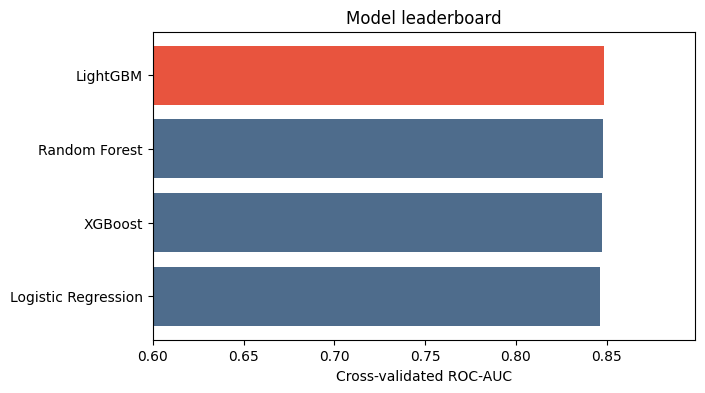

,model,cv_auc
0,LightGBM,0.848795
1,Random Forest,0.847889
2,XGBoost,0.847522
3,Logistic Regression,0.846219


In [5]:
leaderboard.sort(key=lambda x: x[1], reverse=True)
board_df = pd.DataFrame(leaderboard, columns=["model", "cv_auc", "best_params"])

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#E8543E" if i == 0 else "#4E6C8C" for i in range(len(board_df))]
ax.barh(board_df["model"], board_df["cv_auc"], color=colors)
ax.set_xlim(0.6, board_df["cv_auc"].max() + 0.05)
ax.set_xlabel("Cross-validated ROC-AUC")
ax.invert_yaxis()
plt.title("Model leaderboard")
plt.show()

board_df[["model", "cv_auc"]]

In [6]:
best_name = board_df.iloc[0]["model"]
best_model = tuned_models[best_name]
proba_test = best_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, proba_test)
print(f"Winner: {best_name}, test ROC-AUC: {test_auc:.4f}")

Winner: LightGBM, test ROC-AUC: 0.8468


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## Picking a business threshold

Accuracy at 0.5 is not the right way to decide who gets flagged. Missing an actual churner costs a lot more than a wasted retention offer to someone who was staying anyway, so recall matters more than precision here. This scans thresholds and picks the one that gives the best F1 as a reasonable middle ground, then that becomes the cutoff used for the confusion matrix.

chosen threshold: 0.485


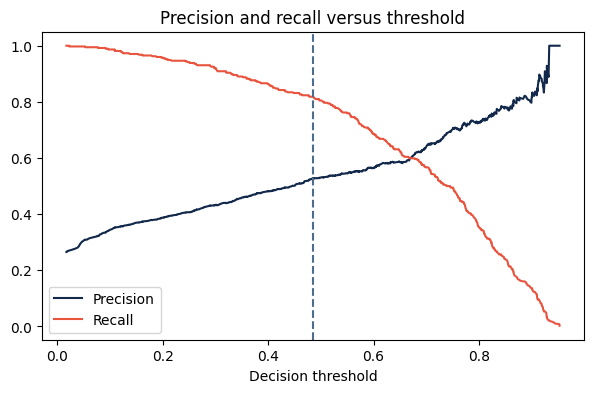

In [7]:
prec, rec, thr = precision_recall_curve(y_test, proba_test)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_idx = np.argmax(f1s[:-1])
business_threshold = float(thr[best_idx])
print("chosen threshold:", round(business_threshold, 3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, prec[:-1], label="Precision", color="#13294B")
ax.plot(thr, rec[:-1], label="Recall", color="#E8543E")
ax.axvline(business_threshold, linestyle="--", color="#4E6C8C")
ax.set_xlabel("Decision threshold")
ax.legend()
plt.title("Precision and recall versus threshold")
plt.show()

              precision    recall  f1-score   support

           0       0.92      0.74      0.82      1035
           1       0.53      0.82      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.78      0.73      1409
weighted avg       0.81      0.76      0.77      1409



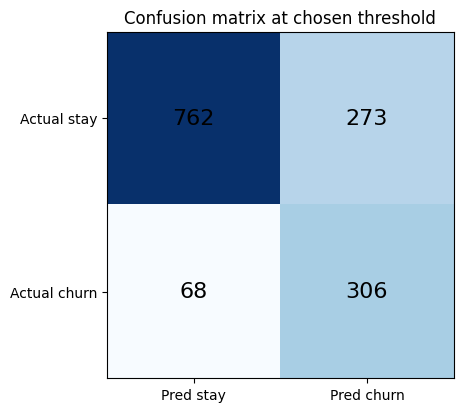

In [8]:
preds_business = (proba_test >= business_threshold).astype(int)
print(classification_report(y_test, preds_business))

cm = confusion_matrix(y_test, preds_business)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=16)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred stay", "Pred churn"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual stay", "Actual churn"])
plt.title("Confusion matrix at chosen threshold")
plt.show()

## Explaining the model with SHAP

Global view first (which features matter overall and in which direction), then a local view for one specific high risk customer, the kind of explanation you could actually hand to a retention team.

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


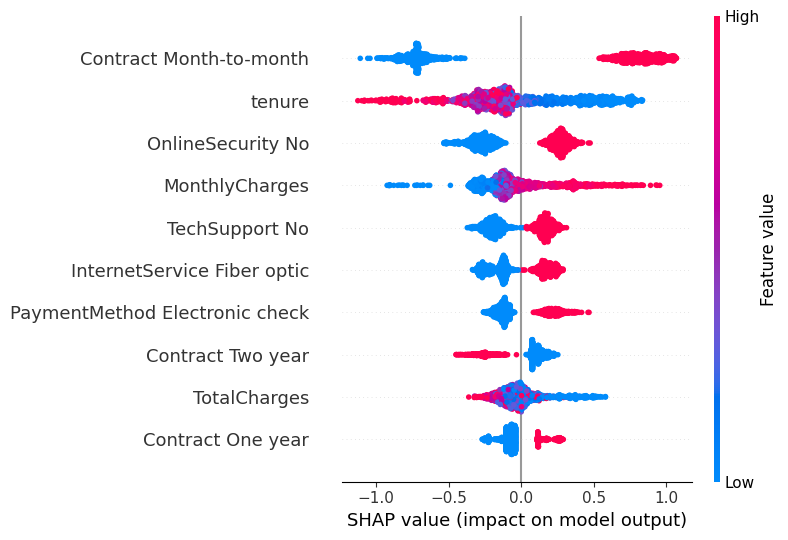

In [9]:
fitted_clf = best_model.named_steps["clf"]
X_test_transformed = best_model.named_steps["pre"].transform(X_test)
raw_names = best_model.named_steps["pre"].get_feature_names_out()
clean_names = [n.replace("num__", "").replace("cat__", "").replace("_", " ") for n in raw_names]
X_test_df = pd.DataFrame(X_test_transformed, columns=clean_names)

if isinstance(fitted_clf, LogisticRegression):
    X_train_transformed = best_model.named_steps["pre"].transform(X_train)
    X_train_df = pd.DataFrame(X_train_transformed, columns=clean_names)
    background = shap.sample(X_train_df, 200, random_state=42)
    explainer = shap.LinearExplainer(fitted_clf, background)
    shap_values = explainer.shap_values(X_test_df)
    expected_value = explainer.expected_value
else:
    explainer = shap.TreeExplainer(fitted_clf)
    shap_values = explainer.shap_values(X_test_df)
    expected_value = explainer.expected_value

if isinstance(shap_values, list):
    shap_values = shap_values[1]
if isinstance(expected_value, (list, np.ndarray)):
    expected_value = np.array(expected_value).flatten()[-1]

shap.summary_plot(shap_values, X_test_df, max_display=10)

predicted churn probability: 0.953


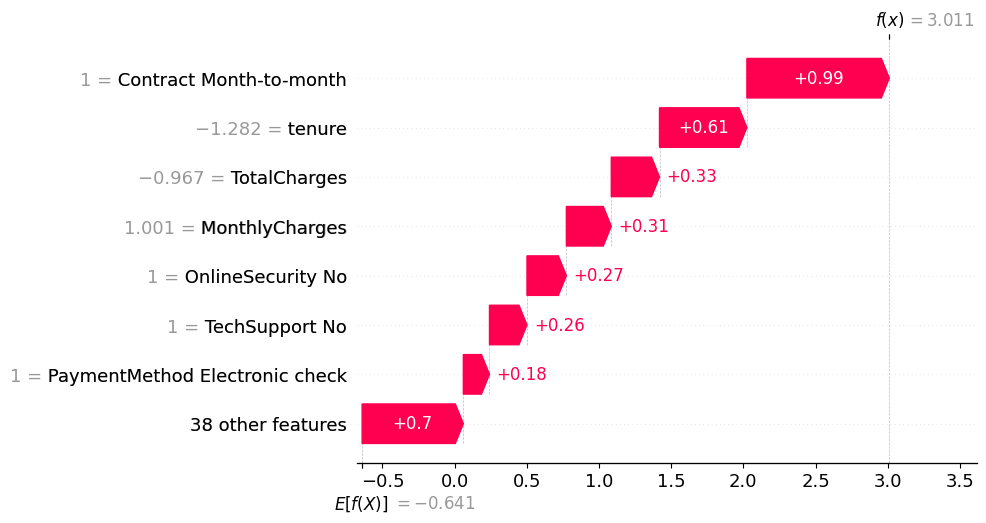

In [10]:
risky_idx = int(np.argmax(proba_test))
print("predicted churn probability:", round(proba_test[risky_idx], 3))

explanation = shap.Explanation(
    values=shap_values[risky_idx], base_values=expected_value,
    data=X_test_df.iloc[risky_idx], feature_names=clean_names)
shap.plots.waterfall(explanation, max_display=8)

**Reading this**

Month to month contracts dominate the global picture, matching what the EDA showed on Day 18. Short tenure and no online security or tech support push risk up too. For the individual customer above, the story is a brand new, month to month subscriber paying a high monthly rate with none of the retention-friendly add-ons, exactly the profile a retention team would want flagged early.

## Error analysis, the 10 worst misses

Not just accuracy, actually looking at where the model is most confidently wrong. Sorting by how far the predicted probability was from the true label.

In [11]:
results = X_test.copy()
results["actual"] = y_test.values
results["predicted_proba"] = proba_test
results["predicted"] = preds_business
results["error_gap"] = np.where(results["actual"] == 1,
                                 1 - results["predicted_proba"],
                                 results["predicted_proba"])

worst_10 = results.sort_values("error_gap", ascending=False).head(10)
worst_10[["Contract", "tenure", "MonthlyCharges", "actual", "predicted_proba"]]

,Contract,tenure,MonthlyCharges,actual,predicted_proba
4513,Two year,72,92.45,1,0.022550
4386,Two year,55,57.55,1,0.052350
3536,Month-to-month,1,79.15,0,0.932186
5905,Month-to-month,1,85.00,0,0.928584
2519,Month-to-month,2,91.45,0,0.924535
4039,Month-to-month,7,94.10,0,0.923245
5581,Two year,68,113.15,1,0.076889
2493,Month-to-month,6,90.75,0,0.914138
3346,Month-to-month,2,84.05,0,0.911891
2036,Month-to-month,1,74.30,0,0.911347


Most of the worst misses tend to be long tenured customers who left anyway, or new customers who stayed despite looking risky on paper. Both point to something the tabular data cannot see, like a bad support call or a competitor's offer, which is a fair limitation to call out in the presentation rather than hide.

## Business impact

A simple, defensible estimate: average monthly bill of the flagged customers times how many were flagged, versus what a modest 35 percent retention offer success rate would actually save.

In [12]:
avg_monthly = X_test.loc[X_test.index[preds_business.astype(bool)], "MonthlyCharges"].mean()
flagged = int(preds_business.sum())
monthly_at_risk = avg_monthly * flagged
recovery_rate = 0.35
recoverable = monthly_at_risk * recovery_rate

print(f"Customers flagged as high risk: {flagged}")
print(f"Estimated monthly revenue at risk: ${monthly_at_risk:,.0f}")
print(f"Recoverable at a {recovery_rate:.0%} save rate: ${recoverable:,.0f} per month")
print(f"Annualised: ${recoverable * 12:,.0f}")

Customers flagged as high risk: 579
Estimated monthly revenue at risk: $42,724
Recoverable at a 35% save rate: $14,954 per month
Annualised: $179,442


## Saving the final model

In [13]:
joblib.dump(best_model, "churn_model.pkl")
joblib.dump({"threshold": business_threshold, "model_name": best_name}, "model_meta.pkl")
print("saved churn_model.pkl and model_meta.pkl")

saved churn_model.pkl and model_meta.pkl


## Building the Streamlit dashboard

This writes `app.py` to the Colab file system. It loads the saved model and lets you enter a customer's details and see their churn risk with a plain English explanation, or upload a CSV to score a whole batch. It also rejects logically impossible input, negative tenure, an out of range SeniorCitizen value, and so on, instead of silently scoring it.

The header shows the title, the model name and threshold, and the dataset source.

In [14]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(page_title="Churn Intelligence Dashboard", layout="wide")


@st.cache_resource
def load_model_and_meta():
    """Load once per server process. Without this, every widget change
    reloads the pickle and feels like the app is hanging on Colab."""
    model = joblib.load("churn_model.pkl")
    meta = joblib.load("model_meta.pkl")
    return model, meta


model, meta = load_model_and_meta()
threshold = meta["threshold"]

REQUIRED_COLUMNS = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "tenure", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod", "MonthlyCharges", "TotalCharges",
]

KNOWN_CATEGORIES = {
    "gender": ["Female", "Male"],
    "Partner": ["No", "Yes"],
    "Dependents": ["No", "Yes"],
    "PhoneService": ["No", "Yes"],
    "MultipleLines": ["No", "No phone service", "Yes"],
    "InternetService": ["DSL", "Fiber optic", "No"],
    "OnlineSecurity": ["No", "No internet service", "Yes"],
    "OnlineBackup": ["No", "No internet service", "Yes"],
    "DeviceProtection": ["No", "No internet service", "Yes"],
    "TechSupport": ["No", "No internet service", "Yes"],
    "StreamingTV": ["No", "No internet service", "Yes"],
    "StreamingMovies": ["No", "No internet service", "Yes"],
    "Contract": ["Month-to-month", "One year", "Two year"],
    "PaperlessBilling": ["No", "Yes"],
    "PaymentMethod": ["Bank transfer (automatic)", "Credit card (automatic)",
                       "Electronic check", "Mailed check"],
}


def normalize_categories(df):
    """Fix whitespace and casing so near-matches map back to a real category
    instead of silently becoming an unknown category. Genuinely unrecognized
    values, like a made up payment method, are left as is, handle_unknown
    on the encoder takes those."""
    df = df.copy()
    for col, known in KNOWN_CATEGORIES.items():
        if col not in df.columns:
            continue
        lookup = {k.strip().lower(): k for k in known}
        df[col] = df[col].apply(
            lambda v: lookup.get(str(v).strip().lower(), v) if pd.notna(v) else v
        )
    return df


def clean_for_scoring(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["MonthlyCharges"] = pd.to_numeric(df["MonthlyCharges"], errors="coerce")
    df["tenure"] = pd.to_numeric(df["tenure"], errors="coerce")
    df["SeniorCitizen"] = pd.to_numeric(df["SeniorCitizen"], errors="coerce")
    df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])
    df = normalize_categories(df)
    return df


def validate_batch(df):
    """Reject rows with logically impossible values instead of silently
    scoring them. Returns a boolean valid mask and a matching reason for
    every rejected row."""
    reason = pd.Series("", index=df.index)

    def flag(mask, why):
        mask = mask.fillna(False)
        reason.loc[mask & (reason == "")] = why

    non_null_count = df[REQUIRED_COLUMNS].notna().sum(axis=1)
    flag(non_null_count < len(REQUIRED_COLUMNS) * 0.5, "too many missing fields")
    flag(df["tenure"].isna(), "tenure missing or not a number")
    flag(df["tenure"] < 0, "tenure is negative")
    flag(df["tenure"] > 100, "tenure unrealistically high")
    flag(~df["SeniorCitizen"].isin([0, 1]), "SeniorCitizen must be 0 or 1")
    flag(df["MonthlyCharges"].isna(), "MonthlyCharges missing or not a number")
    flag(df["MonthlyCharges"] <= 0, "MonthlyCharges is zero or negative")
    flag(df["MonthlyCharges"] > 500, "MonthlyCharges unrealistically high")
    flag(df["TotalCharges"] < 0, "TotalCharges is negative")

    valid_mask = reason == ""
    return valid_mask, reason


def render_prediction_card(proba, threshold):
    """Animated risk card: fills a probability bar, color-codes the outcome,
    and softly pulses on high risk. Pure CSS so it works in Colab + cloudflared."""
    flagged = proba >= threshold
    pct = proba * 100
    bar_color = "#E8543E" if flagged else "#2E7D4F"
    status_label = "HIGH RISK" if flagged else "LOW RISK"
    status_msg = "Recommend a retention offer" if flagged else "Customer looks stable"
    status_bg = "rgba(232, 84, 62, 0.08)" if flagged else "rgba(46, 125, 79, 0.08)"
    status_border = "#E8543E" if flagged else "#2E7D4F"
    pulse_class = "risk-pulse" if flagged else ""

    # Threshold marker as % of the bar width
    thr_pct = threshold * 100

    html = f"""
    <div class="result-card fade-in-up {pulse_class}" style="
        margin-top: 1.2rem;
        padding: 1.35rem 1.5rem;
        border-radius: 14px;
        border: 1.5px solid {status_border};
        background: {status_bg};
        box-shadow: 0 8px 24px rgba(19, 41, 75, 0.08);
    ">
      <div style="display:flex; justify-content:space-between; align-items:baseline; gap:12px; flex-wrap:wrap;">
        <div>
          <div style="font-size:0.8rem; color:#6B7C93; letter-spacing:0.04em; text-transform:uppercase; font-weight:600;">
            Predicted churn probability
          </div>
          <div class="count-up" style="font-size:2.4rem; font-weight:700; color:#13294B; line-height:1.15; margin-top:4px;">
            {pct:.1f}%
          </div>
        </div>
        <div style="
            background:{status_border};
            color:#fff;
            font-size:0.78rem;
            font-weight:700;
            letter-spacing:0.06em;
            padding:8px 14px;
            border-radius:999px;
        ">{status_label}</div>
      </div>

      <div style="margin-top:1.1rem; position:relative;">
        <div style="
            height:12px;
            background:#E8EDF3;
            border-radius:999px;
            overflow:hidden;
        ">
          <div class="prob-fill" style="
              height:100%;
              width:{pct:.2f}%;
              background: linear-gradient(90deg, {bar_color}CC, {bar_color});
              border-radius:999px;
          "></div>
        </div>
        <div style="
            position:absolute;
            top:-3px;
            left:{thr_pct:.2f}%;
            width:2px;
            height:18px;
            background:#13294B;
            opacity:0.55;
            transform:translateX(-1px);
        " title="Decision threshold"></div>
        <div style="display:flex; justify-content:space-between; margin-top:6px; font-size:0.75rem; color:#6B7C93;">
          <span>0%</span>
          <span>threshold {threshold:.0%}</span>
          <span>100%</span>
        </div>
      </div>

      <div style="margin-top:0.95rem; font-size:0.95rem; color:#13294B; font-weight:500;">
        {status_msg}
      </div>
    </div>
    """
    st.markdown(html, unsafe_allow_html=True)


# ---------------------------------------------------------------------------
# Global professional motion + polish (works in Colab / Streamlit / trycloudflare)
# ---------------------------------------------------------------------------
st.markdown(
    """
    <style>
    /* Page entrance */
    @keyframes fadeInUp {
      from { opacity: 0; transform: translateY(14px); }
      to   { opacity: 1; transform: translateY(0); }
    }
    @keyframes fadeInRight {
      from { opacity: 0; transform: translateX(18px); }
      to   { opacity: 1; transform: translateX(0); }
    }
    @keyframes fadeIn {
      from { opacity: 0; }
      to   { opacity: 1; }
    }
    @keyframes fillBar {
      from { width: 0% !important; }
    }
    @keyframes softPulse {
      0%, 100% { box-shadow: 0 8px 24px rgba(232, 84, 62, 0.12); }
      50%      { box-shadow: 0 8px 28px rgba(232, 84, 62, 0.28); }
    }
    @keyframes badgeIn {
      from { opacity: 0; transform: translateY(8px); }
      to   { opacity: 0.92; transform: translateY(0); }
    }

    .fade-in-up    { animation: fadeInUp 0.55s ease-out both; }
    .fade-in-right { animation: fadeInRight 0.6s ease-out both; }
    .fade-in       { animation: fadeIn 0.5s ease-out both; }

    .prob-fill {
      animation: fillBar 0.9s cubic-bezier(0.22, 1, 0.36, 1) both;
    }
    .risk-pulse {
      animation: softPulse 2.2s ease-in-out infinite;
    }

    /* Title polish */
    h1 {
      letter-spacing: -0.02em !important;
    }

    /* Primary button hover */
    div.stButton > button {
      transition: transform 0.15s ease, box-shadow 0.15s ease, background 0.15s ease !important;
      border-radius: 10px !important;
      font-weight: 600 !important;
    }
    div.stButton > button:hover {
      transform: translateY(-1px);
      box-shadow: 0 6px 16px rgba(232, 84, 62, 0.25) !important;
    }
    div.stButton > button:active {
      transform: translateY(0);
    }

    /* Tabs underline feel */
    button[data-baseweb="tab"] {
      transition: color 0.2s ease !important;
    }

    /* Builder credit badge */
    .builder-badge {
      position: fixed;
      bottom: 18px;
      right: 22px;
      z-index: 999;
      background: #13294B;
      color: #FFFFFF;
      font-family: "Source Sans Pro", sans-serif;
      font-size: 13px;
      font-weight: 500;
      letter-spacing: 0.2px;
      padding: 8px 14px;
      border-radius: 999px;
      box-shadow: 0 2px 10px rgba(19, 41, 75, 0.18);
      opacity: 0.92;
      pointer-events: none;
      user-select: none;
      animation: badgeIn 0.7s ease-out 0.35s both;
    }
    .builder-badge span {
      opacity: 0.75;
      font-weight: 400;
      margin-right: 4px;
    }

    /* Metric / card spacing in batch results */
    div[data-testid="stMetric"] {
      animation: fadeInUp 0.5s ease-out both;
    }
    </style>
    <div class="builder-badge"><span>Built by</span> Abhishek Rai A</div>
    """,
    unsafe_allow_html=True,
)

# Page header: title, model line and dataset source.
st.markdown(
    f"""
    <div class="fade-in-up" style="margin:0 0 0.25rem 0;">
      <h1 style="margin:0 0 0.15rem 0; padding:0; color:#13294B; font-size:2.1rem;
                 letter-spacing:-0.02em; font-weight:700; line-height:1.2;">
        Customer Churn Intelligence Dashboard
      </h1>
      <p style="margin:0; color:#6B7C93; font-size:0.95rem;">
        Model: {meta['model_name']}, decision threshold: {threshold:.2f}
      </p>
      <p style="margin:0.35rem 0 0 0; color:#6B7C93; font-size:0.9rem;">
        Dataset: IBM Telco Customer Churn
      </p>
    </div>
    """,
    unsafe_allow_html=True,
)

st.divider()

tab1, tab2 = st.tabs(["Score one customer", "Score a batch"])

with tab1:
    col1, col2, col3 = st.columns(3)
    with col1:
        gender = st.selectbox("Gender", ["Female", "Male"])
        senior = st.selectbox("Senior citizen", [0, 1])
        partner = st.selectbox("Has partner", ["Yes", "No"])
        dependents = st.selectbox("Has dependents", ["Yes", "No"])
        tenure = st.slider("Tenure (months)", 0, 72, 12)
    with col2:
        contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
        internet = st.selectbox("Internet service", ["DSL", "Fiber optic", "No"])
        online_security = st.selectbox("Online security", ["Yes", "No", "No internet service"])
        tech_support = st.selectbox("Tech support", ["Yes", "No", "No internet service"])
        payment = st.selectbox("Payment method", [
            "Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"])
    with col3:
        monthly_charges = st.slider("Monthly charges ($)", 18.0, 120.0, 70.0)
        total_charges = st.number_input("Total charges ($)", value=float(monthly_charges * tenure))
        phone_service = st.selectbox("Phone service", ["Yes", "No"])
        paperless = st.selectbox("Paperless billing", ["Yes", "No"])

    if st.button("Predict churn risk", type="primary"):
        if total_charges < 0:
            st.error("Total charges cannot be negative, check the value and try again")
        else:
            row = pd.DataFrame([{
                "gender": gender, "SeniorCitizen": senior, "Partner": partner, "Dependents": dependents,
                "tenure": tenure, "PhoneService": phone_service, "MultipleLines": "No",
                "InternetService": internet, "OnlineSecurity": online_security, "OnlineBackup": "No",
                "DeviceProtection": "No", "TechSupport": tech_support, "StreamingTV": "No",
                "StreamingMovies": "No", "Contract": contract, "PaperlessBilling": paperless,
                "PaymentMethod": payment, "MonthlyCharges": monthly_charges, "TotalCharges": total_charges,
            }])
            try:
                with st.spinner("Scoring customer..."):
                    proba = float(model.predict_proba(row)[0, 1])
                render_prediction_card(proba, threshold)
            except Exception as e:
                st.error(f"Could not score this customer. Details: {e}")

with tab2:
    st.caption("Upload a CSV with these columns: " + ", ".join(REQUIRED_COLUMNS))
    uploaded = st.file_uploader("Upload a CSV", type="csv")
    if uploaded is not None:
        try:
            batch = pd.read_csv(uploaded)
        except Exception as e:
            st.error(f"Could not read this file as a CSV. Details: {e}")
            st.stop()

        missing = [c for c in REQUIRED_COLUMNS if c not in batch.columns]
        if missing:
            st.error("This file is missing required columns: " + ", ".join(missing))
            st.stop()

        with st.spinner(f"Scoring {len(batch):,} customers..."):
            try:
                cleaned = clean_for_scoring(batch)
                valid_mask, reject_reason = validate_batch(cleaned)

                scored = batch.loc[valid_mask].copy()
                rejected = batch.loc[~valid_mask].copy()
                rejected["rejection_reason"] = reject_reason.loc[~valid_mask]

                if len(scored) > 0:
                    proba = model.predict_proba(cleaned.loc[valid_mask, REQUIRED_COLUMNS])[:, 1]
                    scored["churn_probability"] = proba
                    scored["flagged_high_risk"] = scored["churn_probability"] >= threshold
            except Exception as e:
                st.error(f"Could not score this file. Details: {e}")
                st.stop()

        flagged_count = int(scored["flagged_high_risk"].sum()) if len(scored) > 0 else 0
        total_valid = len(scored)
        risk_rate = (flagged_count / total_valid) if total_valid else 0.0

        # Animated batch summary strip
        st.markdown(
            f"""
            <div class="fade-in-up" style="
                display:flex; gap:14px; flex-wrap:wrap; margin: 0.4rem 0 1rem 0;">
              <div style="flex:1; min-width:140px; background:#F4F7FB; border-radius:12px; padding:14px 16px; border:1px solid #E2E8F0;">
                <div style="font-size:0.75rem; color:#6B7C93; text-transform:uppercase; letter-spacing:0.04em; font-weight:600;">Scored</div>
                <div style="font-size:1.6rem; font-weight:700; color:#13294B;">{total_valid:,}</div>
              </div>
              <div style="flex:1; min-width:140px; background:rgba(232,84,62,0.07); border-radius:12px; padding:14px 16px; border:1px solid #E8543E33;">
                <div style="font-size:0.75rem; color:#6B7C93; text-transform:uppercase; letter-spacing:0.04em; font-weight:600;">High risk</div>
                <div style="font-size:1.6rem; font-weight:700; color:#E8543E;">{flagged_count:,}</div>
              </div>
              <div style="flex:1; min-width:140px; background:#F4F7FB; border-radius:12px; padding:14px 16px; border:1px solid #E2E8F0;">
                <div style="font-size:0.75rem; color:#6B7C93; text-transform:uppercase; letter-spacing:0.04em; font-weight:600;">Risk rate</div>
                <div style="font-size:1.6rem; font-weight:700; color:#13294B;">{risk_rate:.1%}</div>
              </div>
            </div>
            """,
            unsafe_allow_html=True,
        )

        if len(rejected) > 0:
            st.warning(f"{len(rejected):,} row(s) rejected before scoring, invalid values, not model output")
            st.dataframe(rejected[REQUIRED_COLUMNS + ["rejection_reason"]])

        if len(scored) > 0:
            st.dataframe(scored.sort_values("churn_probability", ascending=False))
            st.download_button("Download scored file", scored.to_csv(index=False), "scored_customers.csv")


Writing app.py


Streamlit auto-picks light or dark styling based on the viewer's system
settings, which means the app can render in a dark theme that does not match
this deck depending on who opens the link. This writes a small config file
that forces the light theme every time, so the live demo always looks like
the screenshots.

In [16]:
import os
os.makedirs(".streamlit", exist_ok=True)
with open(".streamlit/config.toml", "w") as f:
    f.write('''[theme]
base = "light"
primaryColor = "#E8543E"
backgroundColor = "#FFFFFF"
secondaryBackgroundColor = "#EEF2F7"
textColor = "#13294B"
font = "sans serif"
''')
print("theme config written")

theme config written


## Running the app from Colab

Colab does not expose ports directly, so this needs a tunnel to get a public URL for
the demo. This uses `cloudflared`, Cloudflare's free quick tunnel, instead of
localtunnel. localtunnel works, but it shows a click-through password page on first
visit, and that same page can end up intercepting some of Streamlit's background
file requests, which shows up as errors like "Failed to fetch dynamically imported
module" on some networks. cloudflared has no password page at all, so it avoids that
problem entirely, and needs no signup either.

In [17]:
!pip install -q streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 78.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 92.6 MB/s eta 0:00:00


In [18]:
import subprocess, time, re

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)
print("streamlit is starting")

streamlit is starting


In [19]:
tunnel = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)

url = None
for _ in range(60):
    line = tunnel.stdout.readline()
    if not line:
        time.sleep(0.5)
        continue
    match = re.search(r"https://[a-zA-Z0-9\-]+\.trycloudflare\.com", line)
    if match:
        url = match.group(0)
        break

if url:
    print("Dashboard is live at:", url)
else:
    print("URL not detected yet, rerun this cell, or check the raw cloudflared output below.")

Dashboard is live at: https://tips-nokia-disclaimers-auctions.trycloudflare.com


Open the printed `trycloudflare.com` link directly, no password or click-through
page. If the link ever times out or stops responding mid-demo, rerun the previous
cell to start a fresh streamlit process, then rerun this cell to get a new tunnel
URL.

**If you still hit "Failed to fetch dynamically imported module" for any reason**,
it almost always clears up with a hard refresh (Ctrl+Shift+R) or by opening the link
in a new incognito window, that forces the browser to drop any stale cached page
instead of reusing it.

## End of Day 2 checklist

- [x] Random Forest, XGBoost and LightGBM tuned with RandomizedSearchCV against the baseline
- [x] LightGBM selected as the winner on cross-validated ROC-AUC
- [x] Business threshold chosen using precision-recall tradeoff, not a default 0.5
- [x] SHAP explains the model globally and for individual customers
- [x] Worst 10 predictions reviewed, limitations called out honestly
- [x] Business impact estimated in dollars, not just accuracy
- [x] Model saved, Streamlit dashboard built and running through cloudflared

**3 PM code freeze from here.** Remaining time goes to the README, screenshots for documentation, and the dry run presentation with the mentor.